Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


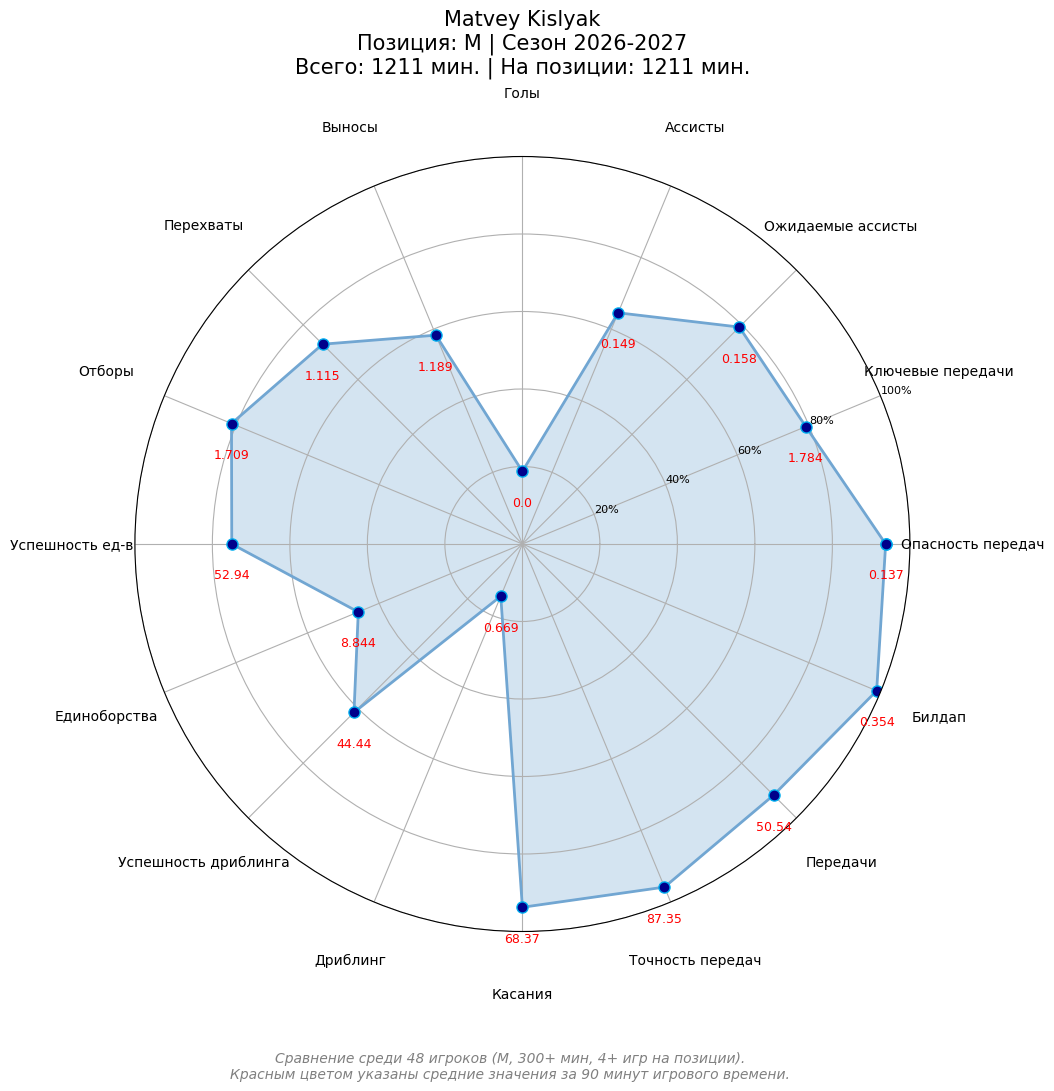

In [ ]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# --- 1. Параметры ---
drive.mount('/content/drive')
DB_PATH = '/content/drive/MyDrive/Data_Bases/rpl.db'
TARGET_PLAYER = 'Matvey Kislyak'
POSITION = 'M'
SEASON = 2027

def run_full_radar_analysis(player_name, position, season, db_path):
    # --- 2. Подключение и определение колонок ---
    conn = sqlite3.connect(db_path)

    v_avg_info = pd.read_sql_query("PRAGMA table_info(V_AVG)", conn)
    pos_col = next((c['name'] for _, c in v_avg_info.iterrows() if 'pos' in c['name'].lower()), 'popular_positions')

    # --- 3. SQL Запрос ---
    query = f'''
    SELECT
        p.player_name,
        SUM(CASE WHEN m.season = {season} THEN ps.minutes_played ELSE 0 END) as total_season_minutes,
        SUM(CASE WHEN ps.position_on_field LIKE "%{position}%" AND m.season = {season} THEN ps.minutes_played ELSE 0 END) as position_minutes,
        round(sum(ps.goals) * 90.0 / sum(ps.minutes_played), 3) as goals,
        round(sum(ps.assists) * 90.0 / sum(ps.minutes_played), 3) as assists,
        round(sum(ps.key_passes) * 90.0 / sum(ps.minutes_played), 3) as key_passes,
        round(sum(ps.xa) * 90.0 / sum(ps.minutes_played), 3) as xa,
        round(sum(ps.clearances) * 90.0 / sum(ps.minutes_played), 3) as clearances,
        round(sum(ps.total_tackles) * 90.0 / sum(ps.minutes_played), 3) as tackles,
        round(sum(ps.interceptions) * 90.0 / sum(ps.minutes_played), 3) as interceptions,
        round(sum(ps.touches) * 90.0 / sum(ps.minutes_played), 2) as touches,
        round(sum(ps.passes_total) * 90.0 / sum(ps.minutes_played), 2) as passes_total,
        round(sum(ps.passes_accurate) * 100.0 / NULLIF(sum(ps.passes_total), 0), 2) as percent_passes,
        round(sum(ps.ground_duels) * 90.0 / sum(ps.minutes_played), 3) as ground_duels,
        round(sum(ps.ground_duels_won) * 100.0 / NULLIF(sum(ps.ground_duels), 0), 2) as percent_ground_duels,
        round(sum(ps.dribble_att) * 90.0 / sum(ps.minutes_played), 3) as dribbles,
        round(sum(ps.dribble_succ) * 100.0 / NULLIF(sum(ps.dribble_att), 0), 2) as percent_dribbles,
        open_play_90 open_play,
        round(sum(ps.xGBuildup) * 90.0 / sum(ps.minutes_played), 3) as buildup
    FROM PlayerStats ps
    JOIN Players p ON ps.player_id = p.player_id
    JOIN Matches m ON ps.match_id = m.match_id
    JOIN (
    WITH EligiblePlayers AS (
    -- ЭТАП 1: Находим игроков с >500 минутами и СЧИТАЕМ ПРАВИЛЬНЫЙ средний рейтинг
    -- Группируем по игроку, чтобы получить данные за все его матчи
    SELECT
        ps.player_id,
        p.player_name,
  		p.player_dob,
        count(*) AS matches,
        SUM(ps.minutes_played) AS minutes,
        AVG(ps.rating) AS final_avg_rating, -- Средний рейтинг за ВСЕ матчи игрока
  		SUM(ps.goals) AS goals,
  		SUM(ps.assists) assists,
   		AVG(ps.shots_on_target)+AVG(ps.shots_off_target)+AVG(ps.shots_blocked) shots,
     	AVG(ps.shots_on_target) on_target,
 		AVG(ps.dribble_succ) dribbles,
		SUM(dribble_succ) * 1.0 / SUM(dribble_att) * 100 pr_drib,
    	AVG(ps.passes_accurate) passes_acc,
		SUM(passes_accurate) * 1.0 / SUM(passes_total) * 100 pr_passes,
      	AVG(ps.crosses_accurate) crosses_acc,
  		AVG(ps.key_passes) key_passes,
  		AVG(ps.clearances) clearances,
   		AVG(ps.total_tackles) tackles,
  		AVG(ps.interceptions) interceptions,
  		AVG(ps.ground_duels_won) ground,
  		SUM(ground_duels_won) * 1.0 / SUM(ground_duels) * 100 pr_ground,
    	AVG(ps.aerial_duels_won) aerial,
  		SUM(aerial_duels_won) * 1.0 / SUM(aerial_duels) * 100 pr_aerial,
		COUNT(*) OVER() cnt
    FROM PlayerStats ps
    JOIN Players p ON ps.player_id = p.player_id
    JOIN Teams t ON ps.team_id = t.team_id
    JOIN Matches m ON ps.match_id = m.match_id
    WHERE m.season = {season}
    GROUP BY ps.player_id, p.player_name, p.player_dob
    HAVING SUM(ps.minutes_played) > 300 -- Фильтруем игроков здесь
),
PositionStats AS (
    -- ЭТАП 2: Считаем количество игр на КАЖДОЙ позиции для КАЖДОГО игрока
    -- Это отдельный расчет, чтобы избежать ошибки с COUNT()
    SELECT
        ps.player_id,
        ps.position_on_field,
        COUNT(*) AS games_on_position
    FROM PlayerStats ps
    JOIN Matches m ON ps.match_id = m.match_id
    WHERE m.season = {season}
    GROUP BY ps.player_id, ps.position_on_field -- Группируем по игроку И позиции!
)
-- ЭТАП 3: Финальная сборка, фильтрация и вывод
SELECT
	RANK() over(order by final_avg_rating desc) '#',
    ep.player_name,
    player_dob,
	(SELECT GROUP_CONCAT(position_data, ', ') FROM (
    SELECT ps_inner.position_on_field || ' (' || ps_inner.games_on_position || ')' AS position_data
    FROM PositionStats ps_inner
    WHERE ps_inner.player_id = ep.player_id
      AND ps_inner.games_on_position > 4
    ORDER BY ps_inner.games_on_position DESC
)) AS popular_positions,
    matches,
    minutes,
    goals,
    assists,
    goals+assists 'g+a',
    ROUND(ep.final_avg_rating, 2) AS avg_rating, -- Берем рейтинг из ЭТАПА 1
    ROUND(shots, 1) || case when (RANK() over(order by shots desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by shots desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by shots desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by shots desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS shots,
    ROUND(on_target, 1) || case when (RANK() over(order by on_target desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by on_target desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by on_target desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by on_target desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS on_target,
    ROUND(key_passes, 1) || case when (RANK() over(order by key_passes desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by key_passes desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by key_passes desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by key_passes desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS key_passes,
     ROUND(passes_acc, 1) || case when (RANK() over(order by passes_acc desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by passes_acc desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by passes_acc desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by passes_acc desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS passes_acc,
     ROUND(pr_passes, 1) || case when (RANK() over(order by pr_passes desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_passes desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_passes desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_passes desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_passes,
    ROUND(crosses_acc, 1) || case when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS crosses_acc,
    ROUND(dribbles, 1) || case when (RANK() over(order by dribbles desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by dribbles desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by dribbles desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by dribbles desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS dribbles,
    ROUND(pr_drib, 1) || case when (RANK() over(order by pr_drib desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_drib desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_drib desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_drib desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_drib,
    ROUND(ground, 1) || case when (RANK() over(order by ground desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by ground desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by ground desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by ground desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS ground,
    ROUND(pr_ground, 1) || case when (RANK() over(order by pr_ground desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_ground desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_ground desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_ground desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_ground,
    ROUND(aerial, 1) || case when (RANK() over(order by aerial desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by aerial desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by aerial desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by aerial desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS aerial,
    ROUND(pr_aerial, 1) || case when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_aerial,
    ROUND(tackles, 1) || case when (RANK() over(order by tackles desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by tackles desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by tackles desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by tackles desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS tackles,
    ROUND(interceptions, 1) || case when (RANK() over(order by interceptions desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by interceptions desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by interceptions desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by interceptions desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS interceptions,
    ROUND(clearances, 1) || case when (RANK() over(order by clearances desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by clearances desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by clearances desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by clearances desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS clearances
FROM EligiblePlayers ep -- Работаем только с игроками из ЭТАПА 1
-- Соединяем с данными о позициях из ЭТАПА 2
JOIN PositionStats ps ON ep.player_id = ps.player_id
WHERE ps.games_on_position > 4
GROUP BY ep.player_id
    ) va ON p.player_name = va.player_name
JOIN (SELECT p.player_name,
 ROUND(SUM(
        COALESCE(x.epv_open_play_acc_n, 0) +
        COALESCE(x.epv_open_play_acc_p, 0) +
        COALESCE(x.epv_open_play_inacc_intercept, 0) +
        COALESCE(x.epv_open_play_inacc_offside, 0) +
        COALESCE(x.epv_open_play_inacc_out, 0)
    ) / NULLIF(SUM(ps.minutes_played), 0) * 90, 3) AS open_play_90
FROM Players p
JOIN PlayerStats ps ON p.player_id = ps.player_id
JOIN xGLab x ON ps.player_stat_id = x.player_stat_id
JOIN Matches m ON ps.match_id = m.match_id
WHERE m.season = {season} GROUP BY p.player_name HAVING SUM(ps.minutes_played) > 300) vr on p.player_name = vr.player_name
    WHERE m.season = {season} AND va.{pos_col} LIKE "%{position}%"
    GROUP BY p.player_name
    HAVING position_minutes > 300
    '''

    df = pd.read_sql_query(query, conn)
    conn.close()

    if player_name not in df['player_name'].values:
        print(f"Игрок {player_name} не найден в выборке для позиции {position}.")
        return

    # --- 4. Расчет процентилей ---
    metrics = ['open_play', 'key_passes', 'xa', 'assists',
               'goals', 'clearances', 'interceptions', 'tackles',
               'percent_ground_duels', 'ground_duels', 'percent_dribbles', 'dribbles',
               'touches', 'percent_passes', 'passes_total', 'buildup']

    for m in metrics:
        df[f'{m}_pct'] = df[m].rank(pct=True) * 100

    # --- 5. Визуализация ---
    translations = {
        'goals': 'Голы', 'assists': 'Ассисты', 'key_passes': 'Ключевые передачи', 'clearances': 'Выносы',
        'tackles': 'Отборы', 'interceptions': 'Перехваты', 'touches': 'Касания', 'passes_total': 'Передачи',
        'percent_passes': 'Точность передач', 'ground_duels': 'Единоборства',
        'percent_ground_duels': 'Успешность ед-в', 'dribbles': 'Дриблинг', 'percent_dribbles': 'Успешность дриблинга',
        'xa' : 'Ожидаемые ассисты', 'buildup' : 'Билдап', 'open_play' : 'Опасность передач'
    }

    player_row = df[df['player_name'] == player_name].iloc[0]
    pct_values = [player_row[f'{m}_pct'] for m in metrics]
    raw_values = [player_row[m] for m in metrics]
    labels = [translations.get(m, m) for m in metrics]

    angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
    pct_plot = pct_values + [pct_values[0]]
    angles_plot = angles + [angles[0]]

    fig, ax = plt.subplots(figsize=(10, 12), subplot_kw=dict(polar=True))

    # Define colors for the plot elements
    line_color = '#71a6d2'
    fill_color = '#71a6d2'
    marker_edge_color = '#00AEEF'  # Turquoise
    marker_face_color = '#00008B'  # Dark Blue
    text_color = 'red'
    grid_text_color = 'black'

    ax.plot(angles_plot, pct_plot, color=line_color, linewidth=2, marker='o', markersize=8, markeredgecolor=marker_edge_color, markerfacecolor=marker_face_color)
    ax.fill(angles_plot, pct_plot, color=fill_color, alpha=0.3)

    for i, angle in enumerate(angles):
        ax.annotate(f'{raw_values[i]}', xy=(angle, pct_values[i]), xytext=(0, -25),
                    textcoords='offset points', ha='center', color=text_color, fontsize=9)

    ax.set_thetagrids(np.degrees(angles), labels, fontsize=10, color=grid_text_color)
    ax.tick_params(axis='x', pad=35)
    ax.set_ylim(0, 100)
    ax.set_yticks([20, 40, 60, 80, 100])
    ax.set_yticklabels(['20%', '40%', '60%', '80%', '100%'], fontsize=8, color=grid_text_color)

    total_min = int(player_row['total_season_minutes'])
    pos_min = int(player_row['position_minutes'])
    title = f"{player_name}\nПозиция: {position} | Сезон {season-1}-{season}\nВсего: {total_min} мин. | На позиции: {pos_min} мин."
    ax.set_title(title, pad=60, size=15, fontweight='normal', color=grid_text_color)

    caption = f"Сравнение среди {len(df)} игроков ({position}, 300+ мин, 4+ игр на позиции).\nКрасным цветом указаны средние значения за 90 минут игрового времени."
    fig.text(0.5, 0.05, caption, ha='center', color='gray', style='italic', fontsize=10)

    plt.show()

run_full_radar_analysis(TARGET_PLAYER, POSITION, SEASON, DB_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


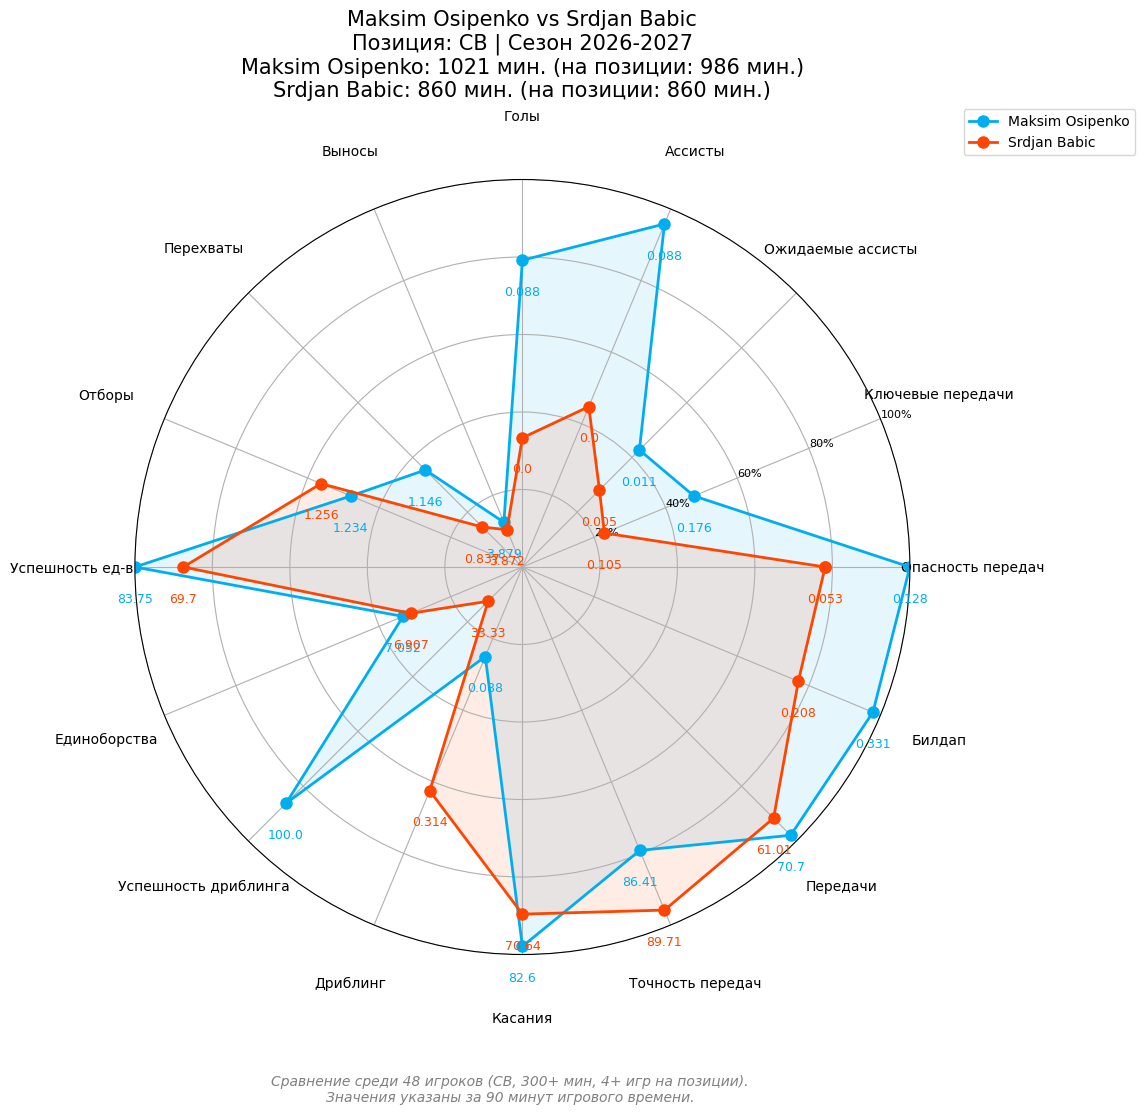

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from google.colab import drive

# --- 1. Параметры ---
drive.mount('/content/drive')
DB_PATH = '/content/drive/MyDrive/Data_Bases/rpl.db'
TARGET_PLAYER_1 = 'Maksim Osipenko'
TARGET_PLAYER_2 = 'Srdjan Babic'
POSITION = 'CB'
SEASON = 2027

def run_full_radar_analysis(player_names, position, season, db_path):
    # --- 2. Подключение и определение колонок ---
    conn = sqlite3.connect(db_path)

    v_avg_info = pd.read_sql_query("PRAGMA table_info(V_AVG)", conn)
    pos_col = next((c['name'] for _, c in v_avg_info.iterrows() if 'pos' in c['name'].lower()), 'popular_positions')

    # --- 3. SQL Запрос ---
    query = f'''
    SELECT
        p.player_name,
        SUM(CASE WHEN m.season = {season} THEN ps.minutes_played ELSE 0 END) as total_season_minutes,
        SUM(CASE WHEN ps.position_on_field LIKE "%{position}%" AND m.season = {season} THEN ps.minutes_played ELSE 0 END) as position_minutes,
        round(sum(ps.goals) * 90.0 / sum(ps.minutes_played), 3) as goals,
        round(sum(ps.assists) * 90.0 / sum(ps.minutes_played), 3) as assists,
        round(sum(ps.key_passes) * 90.0 / sum(ps.minutes_played), 3) as key_passes,
        round(sum(ps.xa) * 90.0 / sum(ps.minutes_played), 3) as xa,
        round(sum(ps.clearances) * 90.0 / sum(ps.minutes_played), 3) as clearances,
        round(sum(ps.total_tackles) * 90.0 / sum(ps.minutes_played), 3) as tackles,
        round(sum(ps.interceptions) * 90.0 / sum(ps.minutes_played), 3) as interceptions,
        round(sum(ps.touches) * 90.0 / sum(ps.minutes_played), 2) as touches,
        round(sum(ps.passes_total) * 90.0 / sum(ps.minutes_played), 2) as passes_total,
        round(sum(ps.passes_accurate) * 100.0 / NULLIF(sum(ps.passes_total), 0), 2) as percent_passes,
        round(sum(ps.ground_duels) * 90.0 / sum(ps.minutes_played), 3) as ground_duels,
        round(sum(ps.ground_duels_won) * 100.0 / NULLIF(sum(ps.ground_duels), 0), 2) as percent_ground_duels,
        round(sum(ps.dribble_att) * 90.0 / sum(ps.minutes_played), 3) as dribbles,
        round(sum(ps.dribble_succ) * 100.0 / NULLIF(sum(ps.dribble_att), 0), 2) as percent_dribbles,
        open_play_90 open_play,
        round(sum(ps.xGBuildup) * 90.0 / sum(ps.minutes_played), 3) as buildup
    FROM PlayerStats ps
    JOIN Players p ON ps.player_id = p.player_id
    JOIN Matches m ON ps.match_id = m.match_id
    JOIN (
    WITH EligiblePlayers AS (
    -- ЭТАП 1: Находим игроков с более 300 минутами и вычисляем их средний рейтинг.
    -- Группируем по игроку, чтобы получить данные за все его матчи
    SELECT
        ps.player_id,
        p.player_name,
  		p.player_dob,
        count(*) AS matches,
        SUM(ps.minutes_played) AS minutes,
        AVG(ps.rating) AS final_avg_rating, -- Средний рейтинг за ВСЕ матчи игрока
  		SUM(ps.goals) AS goals,
  		SUM(ps.assists) assists,
   		AVG(ps.shots_on_target)+AVG(ps.shots_off_target)+AVG(ps.shots_blocked) shots,
     	AVG(ps.shots_on_target) on_target,
 		AVG(ps.dribble_succ) dribbles,
		SUM(dribble_succ) * 1.0 / SUM(dribble_att) * 100 pr_drib,
    	AVG(ps.passes_accurate) passes_acc,
		SUM(passes_accurate) * 1.0 / SUM(passes_total) * 100 pr_passes,
      	AVG(ps.crosses_accurate) crosses_acc,
  		AVG(ps.key_passes) key_passes,
  		AVG(ps.clearances) clearances,
   		AVG(ps.total_tackles) tackles,
  		AVG(ps.interceptions) interceptions,
  		AVG(ps.ground_duels_won) ground,
  		SUM(ground_duels_won) * 1.0 / SUM(ground_duels) * 100 pr_ground,
    	AVG(ps.aerial_duels_won) aerial,
  		SUM(aerial_duels_won) * 1.0 / SUM(aerial_duels) * 100 pr_aerial,
		COUNT(*) OVER() cnt
    FROM PlayerStats ps
    JOIN Players p ON ps.player_id = p.player_id
    JOIN Teams t ON ps.team_id = t.team_id
    JOIN Matches m ON ps.match_id = m.match_id
    WHERE m.season = {season}
    GROUP BY ps.player_id, p.player_name, p.player_dob
    HAVING SUM(ps.minutes_played) > 300 -- Фильтруем игроков здесь
),
PositionStats AS (
    -- ЭТАП 2: Подсчет количества игр на каждой позиции для каждого игрока.
    -- Это отдельный расчет для избежания ошибок с COUNT()
    SELECT
        ps.player_id,
        ps.position_on_field,
        COUNT(*) AS games_on_position
    FROM PlayerStats ps
    JOIN Matches m ON ps.match_id = m.match_id
    WHERE m.season = {season}
    GROUP BY ps.player_id, ps.position_on_field -- Группируем по игроку И позиции!
)
-- ЭТАП 3: Окончательная сборка, фильтрация и вывод
SELECT
	RANK() over(order by final_avg_rating desc) '#',
    ep.player_name,
    player_dob,
	(SELECT GROUP_CONCAT(position_data, ', ') FROM (
    SELECT ps_inner.position_on_field || ' (' || ps_inner.games_on_position || ')' AS position_data
    FROM PositionStats ps_inner
    WHERE ps_inner.player_id = ep.player_id
      AND ps_inner.games_on_position > 2
    ORDER BY ps_inner.games_on_position DESC
)) AS popular_positions,
    matches,
    minutes,
    goals,
    assists,
    goals+assists 'g+a',
    ROUND(ep.final_avg_rating, 2) AS avg_rating, -- Берем рейтинг из ЭТАПА 1
    ROUND(shots, 1) || case when (RANK() over(order by shots desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by shots desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by shots desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by shots desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS shots,
    ROUND(on_target, 1) || case when (RANK() over(order by on_target desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by on_target desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by on_target desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by on_target desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS on_target,
    ROUND(key_passes, 1) || case when (RANK() over(order by key_passes desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by key_passes desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by key_passes desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by key_passes desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS key_passes,
     ROUND(passes_acc, 1) || case when (RANK() over(order by passes_acc desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by passes_acc desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by passes_acc desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by passes_acc desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS passes_acc,
     ROUND(pr_passes, 1) || case when (RANK() over(order by pr_passes desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_passes desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_passes desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_passes desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_passes,
    ROUND(crosses_acc, 1) || case when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by crosses_acc desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS crosses_acc,
    ROUND(dribbles, 1) || case when (RANK() over(order by dribbles desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by dribbles desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by dribbles desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by dribbles desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS dribbles,
    ROUND(pr_drib, 1) || case when (RANK() over(order by pr_drib desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_drib desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_drib desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_drib desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_drib,
    ROUND(ground, 1) || case when (RANK() over(order by ground desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by ground desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by ground desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by ground desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS ground,
    ROUND(pr_ground, 1) || case when (RANK() over(order by pr_ground desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_ground desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_ground desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_ground desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_ground,
    ROUND(aerial, 1) || case when (RANK() over(order by aerial desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by aerial desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by aerial desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by aerial desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS aerial,
    ROUND(pr_aerial, 1) || case when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by pr_aerial desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS pr_aerial,
    ROUND(tackles, 1) || case when (RANK() over(order by tackles desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by tackles desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by tackles desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by tackles desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS tackles,
    ROUND(interceptions, 1) || case when (RANK() over(order by interceptions desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by interceptions desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by interceptions desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by interceptions desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS interceptions,
    ROUND(clearances, 1) || case when (RANK() over(order by clearances desc) * 100.0 / cnt) < 5 then '(S)'
					 when (RANK() over(order by clearances desc) * 100.0 / cnt) between 5 and 10 then '(A)'
					 when (RANK() over(order by clearances desc) * 100.0 / cnt) between 10 and 35 then '(B)'
					 when (RANK() over(order by clearances desc) * 100.0 / cnt) between 35 and 66 then '(C)'
					 else '(D)'
					 end AS clearances
FROM EligiblePlayers ep -- Работаем только с игроками из ЭТАПА 1
-- Соединяем с данными о позициях из ЭТАПА 2
JOIN PositionStats ps ON ep.player_id = ps.player_id
WHERE ps.games_on_position > 2
GROUP BY ep.player_id
    ) va ON p.player_name = va.player_name
JOIN (SELECT p.player_name,
 ROUND(SUM(
        COALESCE(x.epv_open_play_acc_n, 0) +
        COALESCE(x.epv_open_play_acc_p, 0) +
        COALESCE(x.epv_open_play_inacc_intercept, 0) +
        COALESCE(x.epv_open_play_inacc_offside, 0) +
        COALESCE(x.epv_open_play_inacc_out, 0)
    ) / NULLIF(SUM(ps.minutes_played), 0) * 90, 3) AS open_play_90
FROM Players p
JOIN PlayerStats ps ON p.player_id = ps.player_id
JOIN xGLab x ON ps.player_stat_id = x.player_stat_id
JOIN Matches m ON ps.match_id = m.match_id
WHERE m.season = {season} GROUP BY p.player_name HAVING SUM(ps.minutes_played) > 300) vr on p.player_name = vr.player_name
    WHERE m.season = {season} AND va.{pos_col} LIKE "%{position}%"
    GROUP BY p.player_name
    HAVING position_minutes > 300
    '''

    df = pd.read_sql_query(query, conn)
    conn.close()

    for p_name in player_names:
        if p_name not in df['player_name'].values:
            print(f"Игрок {p_name} не найден в выборке для позиции {position}.")
            return

    # --- 4. Расчет процентилей ---
    metrics = ['open_play', 'key_passes', 'xa', 'assists',
               'goals', 'clearances', 'interceptions', 'tackles',
               'percent_ground_duels', 'ground_duels', 'percent_dribbles', 'dribbles',
               'touches', 'percent_passes', 'passes_total', 'buildup']

    for m in metrics:
        df[f'{m}_pct'] = df[m].rank(pct=True) * 100

    # --- 5. Визуализация ---
    translations = {
        'goals': 'Голы', 'assists': 'Ассисты', 'key_passes': 'Ключевые передачи', 'clearances': 'Выносы',
        'tackles': 'Отборы', 'interceptions': 'Перехваты', 'touches': 'Касания', 'passes_total': 'Передачи',
        'percent_passes': 'Точность передач', 'ground_duels': 'Единоборства',
        'percent_ground_duels': 'Успешность ед-в', 'dribbles': 'Дриблинг', 'percent_dribbles': 'Успешность дриблинга',
        'xa' : 'Ожидаемые ассисты', 'buildup' : 'Билдап', 'open_play' : 'Опасность передач'
    }

    labels = [translations.get(m, m) for m in metrics]
    angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()

    fig, ax = plt.subplots(figsize=(10, 12), subplot_kw=dict(polar=True))

    # Определяем цвета для элементов графика
    plot_colors = ['#00AEEF', '#FF4500'] # Бирюзовый для игрока 1, Оранжевый для игрока 2
    # text_color = 'red'
    grid_text_color = 'black'

    for i, player_name in enumerate(player_names):
        player_row = df[df['player_name'] == player_name].iloc[0]
        pct_values = [player_row[f'{m}_pct'] for m in metrics]
        raw_values = [player_row[m] for m in metrics]

        pct_plot = pct_values + [pct_values[0]]
        angles_plot = angles + [angles[0]]

        line_color = plot_colors[i % len(plot_colors)]
        fill_color = plot_colors[i % len(plot_colors)]

        ax.plot(angles_plot, pct_plot, color=line_color, linewidth=2, marker='o', markersize=8, markeredgecolor=line_color, markerfacecolor=line_color, label=player_name)
        ax.fill(angles_plot, pct_plot, color=fill_color, alpha=0.1)

        for j, angle in enumerate(angles):
            ax.annotate(f'{raw_values[j]}', xy=(angle, pct_values[j]), xytext=(0, -25),
                        textcoords='offset points', ha='center', color=line_color, fontsize=9)

    ax.set_thetagrids(np.degrees(angles), labels, fontsize=10, color=grid_text_color)
    ax.tick_params(axis='x', pad=35)
    ax.set_ylim(0, 100)
    ax.set_yticks([20, 40, 60, 80, 100])
    ax.set_yticklabels(['20%', '40%', '60%', '80%', '100%'], fontsize=8, color=grid_text_color)

    # Корректируем заголовок и подпись для двух игроков
    title_players = ' vs '.join(player_names)
    total_min_1 = int(df[df['player_name'] == player_names[0]].iloc[0]['total_season_minutes'])
    pos_min_1 = int(df[df['player_name'] == player_names[0]].iloc[0]['position_minutes'])
    total_min_2 = int(df[df['player_name'] == player_names[1]].iloc[0]['total_season_minutes'])
    pos_min_2 = int(df[df['player_name'] == player_names[1]].iloc[0]['position_minutes'])

    title = f"{title_players}\nПозиция: {position} | Сезон {season-1}-{season}\n{player_names[0]}: {total_min_1} мин. (на позиции: {pos_min_1} мин.)\n{player_names[1]}: {total_min_2} мин. (на позиции: {pos_min_2} мин.)"
    ax.set_title(title, pad=60, size=15, fontweight='normal', color=grid_text_color)

    caption = (f"Сравнение среди {len(df)} игроков ({position}, 300+ мин, 4+ игр на позиции).\n"
               f"Значения указаны за 90 минут игрового времени.") # Скорректированная подпись
    fig.text(0.5, 0.05, caption, ha='center', color='gray', style='italic', fontsize=10)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

    plt.show()

run_full_radar_analysis([TARGET_PLAYER_1, TARGET_PLAYER_2], POSITION, SEASON, DB_PATH)